# Лабораторная работа 2. Декомпозиция ряда с двумя сезонностями

Цель — сравнить классическое разложение, STL и MSTL на одном почасовом ряду. Моделируем 12 недель нагрузки с трендом, суточным и недельным циклами, сдвигом уровня и выбросами. Фиксированные амплитуды задают аддитивную структуру.

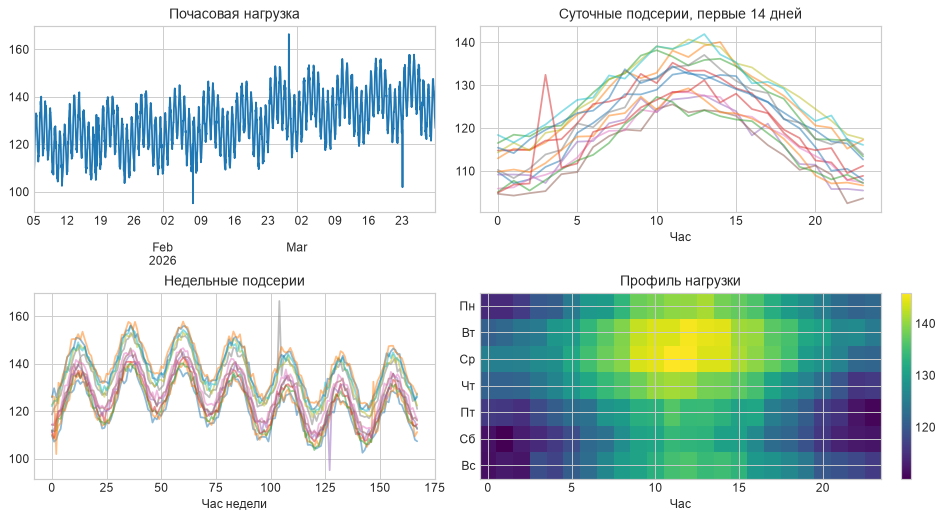

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose, STL, MSTL
from statsmodels.tsa.stattools import acf

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.dpi"] = 85
rng = np.random.default_rng(202)
t = np.arange(12 * 168)
dates = pd.date_range("2026-01-05", periods=len(t), freq="h")
trend = 120 + 0.008 * t + 4 * (t >= 7 * 168)
daily = 11 * np.sin(2 * np.pi * (t - 6) / 24)
weekly = 7 * np.cos(2 * np.pi * (t - 48) / 168)
y = pd.Series(trend + daily + weekly + rng.normal(0, 1.3, size=len(t)),
              index=dates, name="Нагрузка")
y.iloc[[315, 799, 1280, 1850]] += [24, -27, 30, -26]

fig, axes = plt.subplots(2, 2, figsize=(11, 6), layout="constrained")
y.plot(ax=axes[0, 0], title="Почасовая нагрузка")
for phase, group in y.iloc[:336].groupby(y.index[:336].normalize()):
    axes[0, 1].plot(group.index.hour, group, alpha=0.5)
axes[0, 1].set(title="Суточные подсерии, первые 14 дней", xlabel="Час")
for week in np.split(y.to_numpy(), 12):
    axes[1, 0].plot(week, alpha=0.5)
axes[1, 0].set(title="Недельные подсерии", xlabel="Час недели")
profile = y.groupby([dates.day_of_week, dates.hour]).median().unstack()
heatmap = axes[1, 1].imshow(profile, aspect="auto", cmap="viridis")
axes[1, 1].set(yticks=range(7), yticklabels=["Пн","Вт","Ср","Чт","Пт","Сб","Вс"],
               xlabel="Час", title="Профиль нагрузки")
fig.colorbar(heatmap, ax=axes[1, 1])
plt.show()

ACF(24) = 0.889, ACF(168) = 0.848


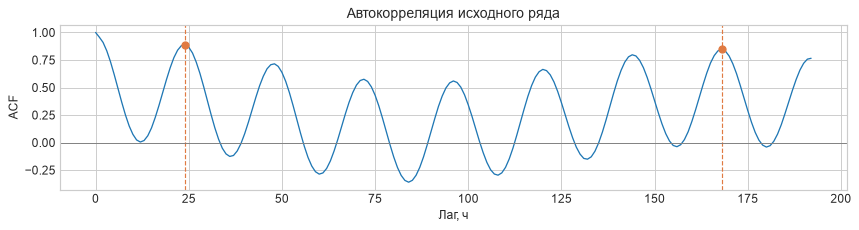

In [2]:
def correlogram(axis, data, title):
    correlations = acf(np.asarray(data), nlags=192, fft=True)
    axis.plot(np.arange(len(correlations)), correlations, lw=1.1)
    for lag in (24, 168):
        axis.axvline(lag, color="#e07a42", ls="--", lw=1)
        axis.scatter(lag, correlations[lag], color="#e07a42", zorder=3)
    axis.axhline(0, color="gray", lw=0.8)
    axis.set(title=title, xlabel="Лаг, ч", ylabel="ACF")
    return correlations[24], correlations[168]

fig, ax = plt.subplots(figsize=(10, 2.6), layout="constrained")
a24, a168 = correlogram(ax, y, "Автокорреляция исходного ряда")
print(f"ACF(24) = {a24:.3f}, ACF(168) = {a168:.3f}")
plt.show()

У сезонного окна STL значение 13 означает сглаживание одноимённых часов по 13 сезонным циклам. Большое окно тренда (169 часов) снижает влияние недельной волны на оценку тренда. Для чёткого сравнения получаем также STL без робастных весов. MSTL оценивает суточную и недельную компоненты поочерёдно.

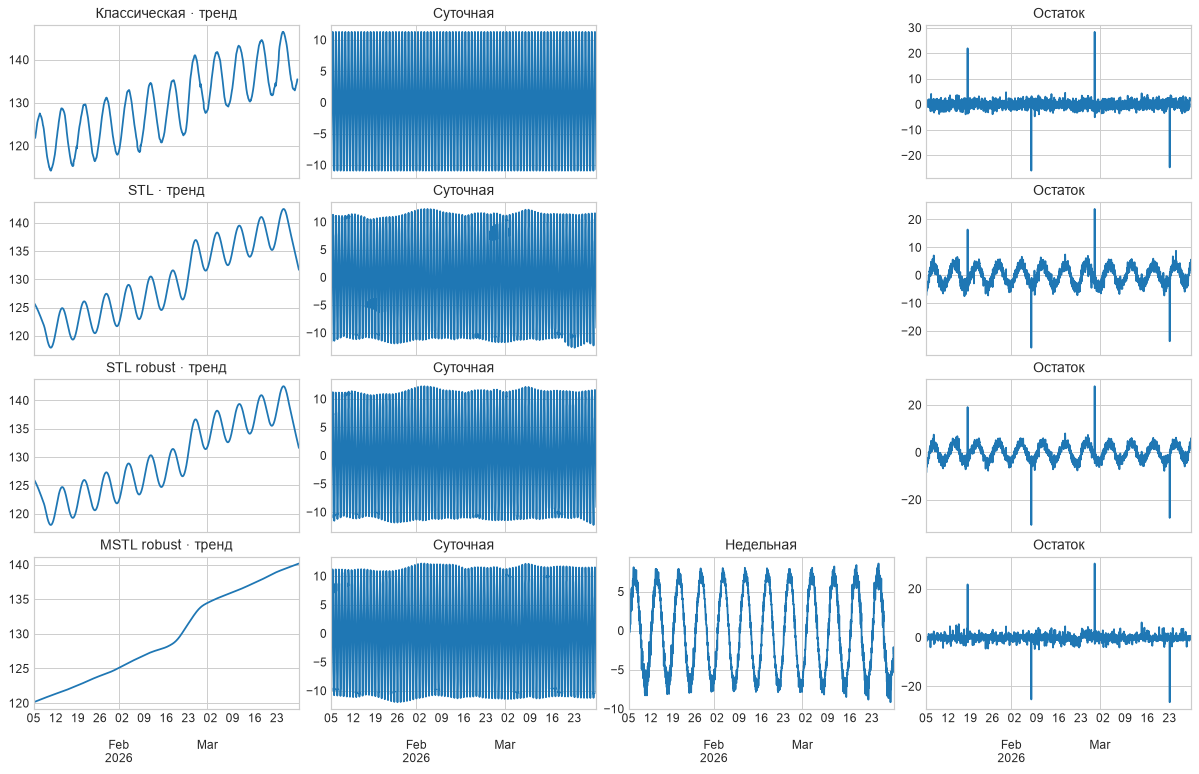

In [3]:
results = {
    "Классическая": seasonal_decompose(y, model="additive", period=24),
    "STL": STL(y, period=24, seasonal=13, trend=169).fit(),
    "STL robust": STL(y, period=24, seasonal=13, trend=169, robust=True).fit(),
    "MSTL robust": MSTL(y, periods=(24, 168), windows=(13, 15),
                       stl_kwargs={"robust": True}).fit(),
}
fig, axes = plt.subplots(4, 4, figsize=(14, 9), sharex=True, layout="constrained")
for row, (name, result) in zip(axes, results.items()):
    result.trend.plot(ax=row[0], title=f"{name} · тренд")
    if isinstance(result.seasonal, pd.DataFrame):
        result.seasonal["seasonal_24"].plot(ax=row[1], title="Суточная")
        result.seasonal["seasonal_168"].plot(ax=row[2], title="Недельная")
    else:
        result.seasonal.plot(ax=row[1], title="Суточная")
        row[2].set_visible(False)
    result.resid.plot(ax=row[3], title="Остаток")
plt.show()

,Дисперсия,ACF(24),ACF(168)
Метод,,,
Классическая,3.0366,0.0170,0.0519
STL,10.4283,0.4012,0.6952
STL robust,11.1766,0.4236,0.6875
MSTL robust,2.7659,-0.0342,-0.0226


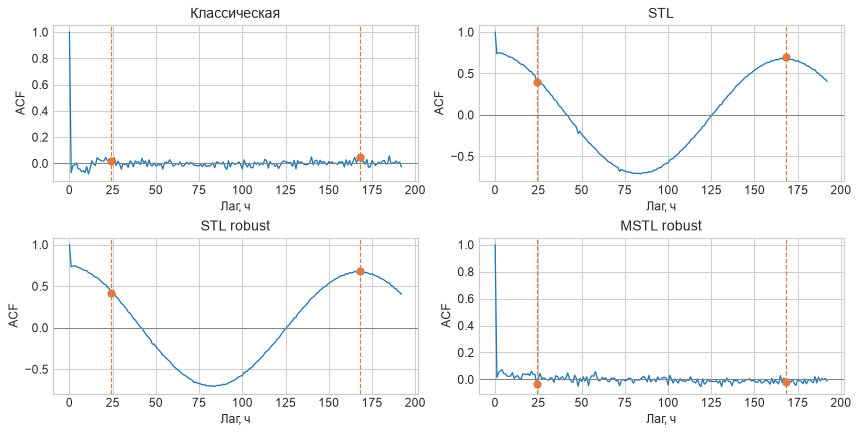

Наименьшая дисперсия остатка: MSTL robust.


In [4]:
# Для всех методов берём один интервал без краевых NaN классического метода.
common = results["Классическая"].resid.dropna().index
fig, axes = plt.subplots(2, 2, figsize=(10, 5), layout="constrained")
comparison = []
for ax, (name, result) in zip(axes.flat, results.items()):
    residual = result.resid.loc[common]
    a24, a168 = correlogram(ax, residual, name)
    comparison.append((name, residual.var(), a24, a168))
scores = pd.DataFrame(comparison, columns=["Метод", "Дисперсия", "ACF(24)", "ACF(168)"]).set_index("Метод")
display(scores.round(4))
plt.show()
print(f"Наименьшая дисперсия остатка: {scores['Дисперсия'].idxmin()}.")

### Выводы

- Декомпозиция с периодом 24 выделяет дневные колебания. У STL и робастного STL недельный цикл остаётся в остатке, где ACF(168) составляет 0,695 и 0,688. У классического метода ACF(168) в остатке равна 0,052, поскольку суточное скользящее среднее пропускает медленную недельную волну в оценку тренда. Поэтому сравниваем и сами компоненты.
- Робастные веса защищают оценки тренда и сезонности от отдельных выбросов. Сами выбросы остаются в остатках, поэтому сравниваем также ACF.
- MSTL выделяет обе сезонности. Дисперсия остатка равна 2,766, а ACF(168) близка к нулю (−0,023). Тренд показывает медленный подъём и сглаженный переход между уровнями. Небольшая остаточная ACF сама по себе не доказывает наличие белого шума.
- Классическая схема подходит для быстрой диагностики устойчивого одиночного цикла. STL полезен при изменении сезонного профиля и выбросах. MSTL позволяет оценить несколько периодов одновременно.